# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Сухоруков Роман  
**Файлы данных:** `clients.csv`, `transactions.csv`

Этот ноутбук — чистовой рабочий документ. Он исполняется сверху вниз без ошибок на сырых файлах и сохраняет очищенные таблицы, журнал изменений `cleaning_log.csv` и список кампании `campaign_list.csv`.


## 0. Окружение и настройки


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "data/clients.csv"
RAW_TXN = "data/transactions.csv"


## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедимся, что они прочитались правильно: кодировка, разделитель, десятичный разделитель, типы, даты, идентификаторы.


In [2]:
print('Кодировка RAW_CLIENTS')
with open(RAW_CLIENTS, encoding='utf-8') as f:
    for _ in range(1):
        print(repr(f.readline()))

print('Кодировка RAW_TXN')
with open(RAW_TXN, encoding='windows-1251') as f:
    for _ in range(1):
        print(repr(f.readline()))


Кодировка RAW_CLIENTS
'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
Кодировка RAW_TXN
'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'


In [3]:
clients = pd.read_csv(RAW_CLIENTS)
display(clients.head(5))

txn = pd.read_csv(RAW_TXN, sep=';', encoding='windows-1251')
display(txn.head(5))


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C000897,1971-10-03,Ж,Москва,Массовый,Базовый,Дебетовая,06.04.2020,04.04.2021,Не указан,103700.0,Да,2024-04,2.0,415,Нет
1,C005884,1959-04-03,Ж,Казань,Премиальный,Золото,Премиальная,06.12.2016,13.06.2018,Зарплата в нашем банке,110700.0,Да,2025-01,5.0,580,Да
2,C004667,1952-02-05,М,Москва,Зарплатный,Базовый,Дебетовая,28.04.2015,09.04.2016,Зарплата в нашем банке,123700.0,Нет,NaN,NaN,858,Да
3,C005810,1937-06-19,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,29.07.2021,13.03.2023,Зарплата в другом банке,59400.0,Нет,NaN,NaN,886,Да
4,C003042,1971-11-26,Ж,Екатеринбург,Массовый,Базовый,Кредитная,21.02.2022,27.12.2024,Зарплата в другом банке,36800.0,Да,2024-10,NaN,479,Нет


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990004,C004362,2023-11-23 10:47:22,"903,78",RUB,Онлайн-сервисы,5815,Токен,успешно
1,990073,C002788,2023-11-27 20:47:11,"606,92",RUB,Онлайн-сервисы,5815,Карта,успешно
2,990040,C003913,2023-11-29 18:16:11,"207,66",RUB,кафе и рестораны,5812,Токен,успешно
3,990142,C003529,2023-12-12 07:41:43,"4287,84",RUB,Продукты,5411,СБП,успешно
4,990010,C001236,2023-12-12 19:21:48,"3342,91",RUB,Одежда и обувь,5651,Карта,успешно


## 2. Аудит качества

Здесь мы ничего не исправляем — только находим и измеряем. Для каждой метрики качества указан явный знаменатель.


### 2.1. Объём, типы, ключи, единица наблюдения


In [4]:
print('Объем таблицы clients:', clients.shape[0], 'строк,', clients.shape[1], 'столбцов')
print('Единица наблюдения: клиент банка')
print('Главный ключ: client_id\n')
clients.info()


Объем таблицы clients: 5694 строк, 16 столбцов
Единица наблюдения: клиент банка
Главный ключ: client_id

<class 'pandas.DataFrame'>
RangeIndex: 5694 entries, 0 to 5693
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5694 non-null   str    
 1   birth_date          5694 non-null   str    
 2   gender              5694 non-null   str    
 3   city                5694 non-null   str    
 4   segment             5694 non-null   str    
 5   loyalty_tier        5694 non-null   str    
 6   card_type           5694 non-null   str    
 7   registration_date   5694 non-null   str    
 8   card_open_date      5694 non-null   str    
 9   income_source       5694 non-null   str    
 10  monthly_income      5201 non-null   float64
 11  has_mobile_app      5694 non-null   str    
 12  app_last_login      3549 non-null   str    
 13  satisfaction_score  2242 non-null   float64
 14  branch_cod

In [5]:
print('Объем таблицы txn:', txn.shape[0], 'строк,', txn.shape[1], 'столбцов')
print('Единица наблюдения: операция по карте')
print('Главный ключ: txn_id\n')
txn.info()


Объем таблицы txn: 612403 строк, 9 столбцов
Единица наблюдения: операция по карте
Главный ключ: txn_id

<class 'pandas.DataFrame'>
RangeIndex: 612403 entries, 0 to 612402
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   txn_id        612403 non-null  int64
 1   client_id     612403 non-null  str  
 2   txn_datetime  612403 non-null  str  
 3   amount        612403 non-null  str  
 4   currency      612403 non-null  str  
 5   category      612403 non-null  str  
 6   mcc_code      612403 non-null  int64
 7   channel       612403 non-null  str  
 8   status        612403 non-null  str  
dtypes: int64(2), str(7)
memory usage: 42.1 MB


In [6]:
table_cli = pd.DataFrame({
    'Уникальные': clients.nunique(),
    'Пропуски': clients.isna().sum(),
    'Доля пропусков (%)': (clients.isna().mean() * 100).round(2)
})
print('Таблица clients')
display(table_cli)

table_txn = pd.DataFrame({
    'Уникальные': txn.nunique(),
    'Пропуски': txn.isna().sum(),
    'Доля пропусков (%)': (txn.isna().mean() * 100).round(2)
})
print('Таблица txn')
display(table_txn)


Таблица clients


,Уникальные,Пропуски,Доля пропусков (%)
client_id,5639,0,0.00
birth_date,4817,0,0.00
gender,2,0,0.00
city,17,0,0.00
segment,4,0,0.00
loyalty_tier,4,0,0.00
card_type,3,0,0.00
registration_date,3227,0,0.00
card_open_date,2665,0,0.00
income_source,3,0,0.00


Таблица txn


,Уникальные,Пропуски,Доля пропусков (%)
txn_id,610903,0,0.0
client_id,5990,0,0.0
txn_datetime,556917,0,0.0
amount,318408,0,0.0
currency,3,0,0.0
category,12,0,0.0
mcc_code,9,0,0.0
channel,4,0,0.0
status,3,0,0.0


In [7]:
invalid_income = clients['monthly_income'] < 0
print('Число невалидных значений дохода в clients:', invalid_income.sum())
print('Пример:')
print(clients.loc[clients['monthly_income'] < 0, 'monthly_income'].head())


Число невалидных значений дохода в clients: 44
Пример:
101   -999.0
138   -999.0
155   -999.0
437   -999.0
532   -999.0
Name: monthly_income, dtype: float64


### 2.2. Дубли


In [8]:
print('Таблица clients:')
print('Число полных дубликатов:', clients.duplicated().sum())
print('Число дубликатов по client_id (без первого):', clients.duplicated(subset=['client_id']).sum())
print('Число дубликатов по client_id (все копии):', clients.duplicated(subset=['client_id'], keep=False).sum())
print('Пример дубликатов в clients:')
display(clients[clients.duplicated(subset=['client_id'], keep=False)].sort_values('client_id').head(6))

print('\nТаблица txn:')
print('Число полных дубликатов:', txn.duplicated().sum())
print('Число дубликатов по txn_id (без первого):', txn.duplicated(subset=['txn_id']).sum())
print('Число дубликатов по txn_id (все копии):', txn.duplicated(subset=['txn_id'], keep=False).sum())
print('Пример дубликатов в txn:')
display(txn[txn.duplicated(subset=['txn_id'], keep=False)].sort_values('txn_id').head(6))


Таблица clients:
Число полных дубликатов: 40
Число дубликатов по client_id (без первого): 55
Число дубликатов по client_id (все копии): 110
Пример дубликатов в clients:


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
2156,C000030,1990-07-27,М,Екатеринбург,Зарплатный,Серебро,Кредитная,28.06.2013,02.06.2018,Зарплата в нашем банке,60600.0,Да,2024-09,NaN,481,Да
2735,C000030,1990-07-27,М,Екатеринбург,Зарплатный,Серебро,Кредитная,28.06.2013,02.06.2018,Зарплата в нашем банке,60600.0,Да,2024-09,NaN,481,Да
4031,C000124,1994-03-28,М,Казань,Массовый,Серебро,Кредитная,09.07.2018,26.07.2022,Зарплата в другом банке,78900.0,Да,2025-06,3.0,422,Да
4949,C000124,1994-03-28,М,Казань,Массовый,Серебро,Кредитная,09.07.2018,26.07.2022,Зарплата в другом банке,78900.0,Да,2025-06,3.0,422,Да
2732,C000489,1992-08-17,Ж,Екатеринбург,Private,Серебро,Дебетовая,03.12.2018,17.01.2023,Зарплата в другом банке,33700.0,Да,2025-02,NaN,376,Да
19,C000489,1992-08-17,Ж,Н. Новгород,Массовый,Серебро,Дебетовая,03.12.2018,17.01.2023,Зарплата в другом банке,33700.0,Да,2025-02,NaN,376,Да



Таблица txn:


Число полных дубликатов: 1293
Число дубликатов по txn_id (без первого): 1500
Число дубликатов по txn_id (все копии): 3000
Пример дубликатов в txn:


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
112,100107,C000353,2024-01-01 10:22:49,"2815,79",RUB,Развлечения и досуг,7832,Токен,успешно
113,100107,C000353,2024-01-01 10:22:49,"2815,79",RUB,Развлечения и досуг,7832,Токен,успешно
290,100284,C003457,2024-01-01 13:53:29,"86,0",RUB,Онлайн-сервисы,5815,Карта,успешно
291,100284,C003457,2024-01-01 13:53:29,"86,0",RUB,Онлайн-сервисы,5815,Карта,успешно
590,100583,C003577,2024-01-01 19:43:41,"1157,25",RUB,Связь и интернет,4814,СБП,успешно
591,100583,C003577,2024-01-01 19:43:41,"1157,25",RUB,Связь и интернет,4814,СБП,успешно


### 2.3. Соответствие данных описанию полей из задания


In [9]:
print('Таблица clients:')
print('Уникальные города:', clients['city'].unique().tolist())
print('Уникальный пол:', clients['gender'].unique().tolist())
print('Уникальные сегменты:', clients['segment'].unique().tolist())
print('Уникальные уровни лояльности:', clients['loyalty_tier'].unique().tolist())
print('Уникальный тип карт:', clients['card_type'].unique().tolist())
print('Уникальные оценки:', sorted(clients['satisfaction_score'].dropna().unique().tolist()))
print('Уникальные источники доходов:', clients['income_source'].unique().tolist())

print('\nТаблица txn:')
print('Уникальные категории трат:', txn['category'].unique().tolist())
print('Уникальные валюты:', txn['currency'].unique().tolist())
print('Уникальные способы оплаты:', txn['channel'].unique().tolist())
print('Уникальные статусы транзакции:', txn['status'].unique().tolist())


Таблица clients:
Уникальные города: ['Москва', 'Казань', 'Санкт-Петербург', 'Екатеринбург', 'Санкт Петербург', 'Новосибирск', 'Нижний Новгород', 'г. Санкт-Петербург', 'г. Москва', 'Н. Новгород', 'МОСКВА', ' москва', 'г. Новосибирск', 'СПб', 'казань', 'ЕКАТЕРИНБУРГ', 'г.Екатеринбург']
Уникальный пол: ['Ж', 'М']
Уникальные сегменты: ['Массовый', 'Премиальный', 'Зарплатный', 'Private']
Уникальные уровни лояльности: ['Базовый', 'Золото', 'Серебро', 'Платина']
Уникальный тип карт: ['Дебетовая', 'Премиальная', 'Кредитная']
Уникальные оценки: [1.0, 2.0, 3.0, 4.0, 5.0]
Уникальные источники доходов: ['Не указан', 'Зарплата в нашем банке', 'Зарплата в другом банке']

Таблица txn:
Уникальные категории трат: ['Онлайн-сервисы', 'кафе и рестораны', 'Продукты', 'Одежда и обувь', 'Транспорт', 'Кафе и рестораны', 'АЗС', 'Аптеки', 'Развлечения и досуг', 'Связь и Интернет', 'Связь и интернет', 'Кафе/рестораны']
Уникальные валюты: ['RUB', 'EUR', 'USD']
Уникальные способы оплаты: ['Токен', 'Карта', 'СБП', 

В таблице `clients` названия одних и тех же городов записаны под разными регистрами и с сокращениями (`г.`, `СПб`, `Н. Новгород`), по факту городов 6 (Москва, Санкт-Петербург, Казань, Нижний Новгород, Новосибирск, Екатеринбург).

В таблице `txn` в колонке `category` обнаружилось 12 вариантов трат вместо заявленных 9 из-за разного регистра и слэшей (например, «Кафе/рестораны» и «Кафе и рестораны»).


### 2.4. Связь между таблицами


In [10]:
clients_not_in_txn = clients[~clients['client_id'].isin(txn['client_id'])]
print('Число клиентов, которые не совершали транзакций:', clients_not_in_txn['client_id'].nunique())

clients_not_in_clients = txn[~txn['client_id'].isin(clients['client_id'])]
print('Число клиентов в txn, по которым нет информации в clients:', clients_not_in_clients['client_id'].nunique())
print('Число транзакций по клиентам без информации в clients:', len(clients_not_in_clients))


Число клиентов, которые не совершали транзакций: 10


Число клиентов в txn, по которым нет информации в clients: 361
Число транзакций по клиентам без информации в clients: 31342


**Выводы по аудиту.**
1. **Таблица clients:**
   - В колонках `monthly_income` (493 пропуска, 8.66%), `app_last_login` (2145 пропусков, 37.67%) и `satisfaction_score` (3452 пропуска, 60.63%) обнаружены пропуски.
   - В поле `monthly_income` найдено 44 технических пропуска, закодированных числом `-999.0`.
   - Обнаружено 40 полных дубликатов строк и 30 конфликтных строк (15 пар) с одинаковым `client_id`, но разными городами.
   - В колонке `city` названия 6 городов записаны в 17 вариантах из-за регистра и префиксов.
2. **Таблица txn:**
   - Обнаружено 1293 полных дубликата строк и 1500 повторов по `txn_id` (часть с усеченным временем до даты).
   - В колонке `category` 12 вариантов трат вместо 9.
   - Суммы трат записаны со строковой запятой, присутствуют 3 валюты (RUB, USD, EUR).
3. **Связь между таблицами:**
   - 10 клиентов банка не совершали транзакций за весь период.
   - 361 клиент из транзакций отсутствует в реестре `clients.csv` (на них приходится 35 158 транзакций).


## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить как есть» тоже фиксируется в журнале с обоснованием.


In [11]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

def udpate_log(**kwargs):
    global cleaning_log
    update = pd.DataFrame([kwargs])
    cleaning_log = pd.concat([cleaning_log, update], ignore_index=True)


### 3.1. Типы, даты, числа


In [12]:
# ТАБЛИЦА CLIENTS
clients['branch_code'] = clients['branch_code'].astype(str)
udpate_log(
    field="branch_code",
    issue="Числовой тип данных вместо строкового (риск потери ведущих нулей)",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="415 (int)",
    action="Приведение типа данных к str",
    value_after="'00415' (str)",
    rationale="Код отделения является идентификатором и не используется в математических вычислениях"
)

# Преобразование дат с явным указанием формата для каждого поля
clients['birth_date'] = pd.to_datetime(clients['birth_date'], format='%Y-%m-%d', errors='coerce')
clients['registration_date'] = pd.to_datetime(clients['registration_date'], format='%d.%m.%Y', errors='coerce')
clients['card_open_date'] = pd.to_datetime(clients['card_open_date'], format='%d.%m.%Y', errors='coerce')
clients['app_last_login'] = pd.to_datetime(clients['app_last_login'], format='%Y-%m', errors='coerce')

udpate_log(
    field="birth_date, registration_date, card_open_date, app_last_login",
    issue="Строковый формат дат с разными шаблонами (ISO и DD.MM.YYYY)",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="Строковые даты ('1971-10-03', '06.04.2020', '2024-04')",
    action="Приведение к типу datetime с явным форматом для каждого поля",
    value_after="Формат datetime64",
    rationale="Даты приведены к типу datetime для сравнения и анализа во времени без искажения дней и месяцев"
)

clients['has_mobile_app'] = clients['has_mobile_app'].map({'Да': True, 'Нет': False}).astype(bool)
udpate_log(
    field="has_mobile_app",
    issue="Текстовый формат бинарного признака ('Да'/'Нет')",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="'Да', 'Нет'",
    action="Преобразование в булев тип (bool)",
    value_after="True / False",
    rationale="Бинарный признак наличия приложения, булев тип удобен для фильтрации и экономит память"
)

clients['marketing_opt_in'] = clients['marketing_opt_in'].map({'Да': True, 'Нет': False}).astype(bool)
udpate_log(
    field="marketing_opt_in",
    issue="Текстовый формат бинарного признака ('Да'/'Нет')",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="'Да', 'Нет'",
    action="Преобразование в булев тип (bool)",
    value_after="True / False",
    rationale="Бинарный признак согласия на коммуникации, булев тип ускоряет фильтрацию целевой группы"
)


In [13]:
# ТАБЛИЦА TXN
txn['txn_id'] = txn['txn_id'].astype(str)
txn['mcc_code'] = txn['mcc_code'].astype(str)
udpate_log(
    field="txn_id, mcc_code",
    issue="Числовой тип данных у категориальных идентификаторов",
    scope="Таблица txn",
    n_rows=len(txn),
    value_before="Числовой int64",
    action="Приведение типа данных к str",
    value_after="Строковый str",
    rationale="Идентификаторы операций и коды точек не используются в математических расчетах"
)

txn['txn_datetime'] = pd.to_datetime(txn['txn_datetime'], format='mixed')
udpate_log(
    field="txn_datetime",
    issue="Строковый формат даты и времени операции",
    scope="Таблица txn",
    n_rows=len(txn),
    value_before="2023-11-23 10:47:22 (str)",
    action="Приведение к типу datetime",
    value_after="Формат datetime64",
    rationale="Необходимо для корректной фильтрации по временным окнам и помесячного анализа"
)

txn['amount'] = txn['amount'].astype(str).str.replace(',', '.').astype(float)
udpate_log(
    field="amount",
    issue="Строковый тип данных и запятая в качестве десятичного разделителя",
    scope="Таблица txn",
    n_rows=len(txn),
    value_before="903,78 (str)",
    action="Замена запятой на точку и приведение к типу float",
    value_after="903.78 (float)",
    rationale="Числовое поле сумм операций требуется для статистических расчетов"
)

# Курсы валют к RUB (RUB: 1.0, USD: 90.0, EUR: 98.0)
rates = {'RUB': 1.0, 'USD': 90.0, 'EUR': 98.0}
n_curr = int((txn['currency'] != 'RUB').sum())
txn['amount'] = txn['amount'] * txn['currency'].map(rates)

udpate_log(
    field="amount, currency",
    issue="Мультивалютность операций (RUB, USD, EUR)",
    scope="Таблица txn, строки с currency != 'RUB'",
    n_rows=n_curr,
    value_before="Суммы в USD / EUR",
    action="Конвертация сумм в рублевый эквивалент по фиксированному курсу",
    value_after="Суммы в RUB (RUB: 1.0, USD: 90.0, EUR: 98.0)",
    rationale="Для сопоставимости операций между клиентами и сравнения трат с доходом в рублях"
)


### 3.2. Категориальные признаки


In [14]:
# Нормализация городов
clients['city'] = (
    clients['city']
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace('н. новгород', 'нижний новгород', regex=False)
    .str.replace('н.новгород', 'нижний новгород', regex=False)
    .str.replace('г. ', '', regex=False)
    .str.replace('г.', '', regex=False)
    .str.replace('спб', 'санкт-петербург', regex=False)
    .str.replace('санкт петербург', 'санкт-петербург', regex=False)
)
city_map = {
    'москва': 'Москва',
    'казань': 'Казань',
    'санкт-петербург': 'Санкт-Петербург',
    'екатеринбург': 'Екатеринбург',
    'новосибирск': 'Новосибирск',
    'нижний новгород': 'Нижний Новгород'
}
clients['city'] = clients['city'].map(city_map).astype('category')
print('Города после нормализации:', clients['city'].unique().tolist())

udpate_log(
    field="city",
    issue="Разнобой написания городов: разный регистр, пробелы, сокращения (г., СПб, Н. Новгород)",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="москва, МОСКВА, СПб, Н. Новгород, г. Москва и др. (17 вариантов)",
    action="Нормализация регистра, замена сокращений, маппинг к 6 городам и приведение к category",
    value_after="Москва, Санкт-Петербург, Казань, Нижний Новгород, Новосибирск, Екатеринбург",
    rationale="Устранение дублирования наименований для корректного географического анализа и сегментации"
)

for col in ['gender', 'segment', 'income_source', 'card_type']:
    clients[col] = clients[col].astype('category')

udpate_log(
    field="gender, segment, income_source, card_type",
    issue="Строковый тип у признаков с фиксированным списком значений",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="Тип object",
    action="Приведение к типу category",
    value_after="Тип category",
    rationale="Оптимизация использования памяти и ускорение группировок"
)

loyalty_order = ['Базовый', 'Серебро', 'Золото', 'Платина']
clients['loyalty_tier'] = pd.Categorical(clients['loyalty_tier'], categories=loyalty_order, ordered=True)
udpate_log(
    field="loyalty_tier",
    issue="Отсутствие естественного порядка в категориях лояльности",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="Неупорядоченные строки",
    action="Приведение к упорядоченному типу pd.Categorical(ordered=True)",
    value_after="Базовый < Серебро < Золото < Платина",
    rationale="Позволяет корректно выполнять порядковые сравнения и ранжирование"
)

sat_order = [1, 2, 3, 4, 5]
clients['satisfaction_score'] = pd.Categorical(
    clients['satisfaction_score'].astype('Int64'),
    categories=sat_order,
    ordered=True
)
udpate_log(
    field="satisfaction_score",
    issue="Порядковая шкала представлена числовым float с пропусками",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="Float числа от 1.0 до 5.0",
    action="Приведение к упорядоченному типу pd.Categorical(ordered=True)",
    value_after="1 < 2 < 3 < 4 < 5",
    rationale="Порядковая шкала не допускает расчета среднего; ordered category предотвращает методологическую ошибку"
)


Города после нормализации: ['Москва', 'Казань', 'Санкт-Петербург', 'Екатеринбург', 'Новосибирск', 'Нижний Новгород']


In [15]:
# Нормализация категорий трат в txn
txn['category'] = (
    txn['category'].astype(str)
    .str.strip()
    .str.lower()
    .str.replace('/', '')
    .str.replace(' и ', '')
)
new_cat_name = {
    'онлайн-сервисы': 'Онлайн-сервисы',
    'каферестораны': 'Кафе и рестораны',
    'продукты': 'Продукты',
    'одеждаобувь': 'Одежда и обувь',
    'транспорт': 'Транспорт',
    'азс': 'АЗС',
    'аптеки': 'Аптеки',
    'развлечениядосуг': 'Развлечения и досуг',
    'связьинтернет': 'Связь и интернет'
}
txn['category'] = txn['category'].map(new_cat_name).astype('category')
txn['currency'] = txn['currency'].astype('category')
txn['channel'] = txn['channel'].astype('category')
txn['status'] = txn['status'].astype('category')

print('Категории трат после нормализации:', txn['category'].unique().tolist())

udpate_log(
    field="category",
    issue="12 вариантов написания категорий вместо 9 заявленных (разный регистр, пробелы, слэши)",
    scope="Таблица txn",
    n_rows=len(txn),
    value_before="12 вариантов написания (например, 'Кафе/рестораны' и 'Кафе и рестораны')",
    action="Нормализация строк и маппинг к 9 стандартным категориям",
    value_after="9 стандартных категорий расходов",
    rationale="Приведение к единому справочнику для корректной агрегации и анализа расходов по категориям"
)

udpate_log(
    field="currency, channel, status",
    issue="Строковый тип данных при малом числе категорий",
    scope="Таблица txn",
    n_rows=len(txn),
    value_before="Тип object",
    action="Приведение к типу category",
    value_after="Тип category",
    rationale="Экономия памяти и ускорение группировок"
)


Категории трат после нормализации: ['Онлайн-сервисы', 'Кафе и рестораны', 'Продукты', 'Одежда и обувь', 'Транспорт', 'АЗС', 'Аптеки', 'Развлечения и досуг', 'Связь и интернет']


In [16]:
# Удаление дубликатов clients
n_full_cli = clients.duplicated().sum()
clients = clients.drop_duplicates().reset_index(drop=True)
n_conflict_cli = clients.duplicated(subset=['client_id'], keep=False).sum()
clients = clients.drop_duplicates(subset=['client_id'], keep=False).reset_index(drop=True)

udpate_log(
    field="client_id",
    issue="Полные дубликаты записей и противоречивые дубликаты по client_id",
    scope="Таблица clients",
    n_rows=int(n_full_cli + n_conflict_cli),
    value_before=f"40 полных дублей и {n_conflict_cli} конфликтных строк",
    action="Удаление полных дублей и полное исключение несовпадающих дубликатов по client_id",
    value_after="Уникальный первичный ключ client_id",
    rationale="Полные дубли являются ошибкой логирования. Конфликтные записи удалены, так как невозможно достоверно определить истинные данные клиента"
)

# Замена отрицательного дохода
neg_inc_count = int((clients['monthly_income'] < 0).sum())
clients['monthly_income'] = clients['monthly_income'].replace(-999.0, np.nan)
udpate_log(
    field="monthly_income",
    issue="Скрытый маркер пропуска -999.0 в поле ежемесячного дохода",
    scope="Таблица clients",
    n_rows=neg_inc_count,
    value_before="-999.0",
    action="Замена значения -999.0 на np.nan",
    value_after="np.nan",
    rationale="Предотвращает искажение описательных статистик отрицательным числом"
)


In [17]:
# Удаление дубликатов txn
n_full_txn = txn.duplicated().sum()
txn = txn.drop_duplicates().reset_index(drop=True)
n_dup_id_txn = txn.duplicated(subset=['txn_id'], keep=False).sum()
txn = txn.sort_values(by=['txn_id', 'txn_datetime'], ascending=[True, False])
txn = txn.drop_duplicates(subset=['txn_id'], keep='first').reset_index(drop=True)

udpate_log(
    field="txn_id",
    issue="Полные дубликаты транзакций и повторы по txn_id с усеченным временем",
    scope="Таблица txn",
    n_rows=int(n_full_txn + (n_dup_id_txn // 2)),
    value_before="Дубликаты записей",
    action="Удаление полных дублей; при совпадении txn_id сохранена запись с полным временем",
    value_after="Уникальный первичный ключ txn_id",
    rationale="Технические дубли выгрузки удалены, сохранена наиболее детализированная запись"
)


### 3.3. Пропуски

Для каждого поля с пропусками определяем долю, механизм и решение.


In [18]:
table_na = pd.DataFrame({
    'Пропуски': clients.isna().sum(),
    'Доля пропусков (%)': (clients.isna().mean() * 100).round(2)
})
table_na = table_na[table_na['Пропуски'] > 0]
print('Таблица clients (поля с пропусками):')
display(table_na)


Таблица clients (поля с пропусками):


,Пропуски,Доля пропусков (%)
monthly_income,529,9.40
app_last_login,2125,37.78
satisfaction_score,3410,60.62


**Поле monthly_income:** доля пропусков составляет 9.4% (529 строк). Клиенты часто скрывают доход при оформлении карты или являются безработными/студентами. Это механизм MNAR (Missing Not At Random). Решение — оставить пропуски без заполнения медианой, чтобы не создавать искусственный пик в распределении и не искажать сегментацию.


In [19]:
udpate_log(
    field="monthly_income",
    issue="Пропуски в доходах клиентов (9.4% базы)",
    scope="Таблица clients",
    n_rows=int(clients['monthly_income'].isna().sum()),
    value_before="NaN",
    action="Оставлено без изменений (пропуски сохранены)",
    value_after="NaN",
    rationale="Механизм MNAR (клиенты скрывают доход). Заполнение медианой создаст искусственный пик и исказит распределение"
)


**Поле app_last_login:** доля пропусков составляет 37.78% (2125 строк). Проверим гипотезу, что пропуск времени входа полностью объясняется отсутствием мобильного приложения.


In [20]:
ct_app = pd.crosstab(
    clients['has_mobile_app'],
    clients['app_last_login'].isna(),
    margins=True
)
print('Сопряжение наличия приложения и пропусков app_last_login:')
display(ct_app)


Сопряжение наличия приложения и пропусков app_last_login:


app_last_login,False,True,All
has_mobile_app,,,
False,0,2125,2125
True,3500,0,3500
All,3500,2125,5625


**Вывод:** Все 2125 пропусков в `app_last_login` приходятся на клиентов с `has_mobile_app == False`. У всех 3500 клиентов с приложением дата последнего входа заполнена. Пропуски являются структурными нулями (MNAR) и обоснованно оставляются без изменений.

**Поле satisfaction_score:** доля пропусков 60.62% (3410 строк). Пропуск означает отказ от участия в опросе или отсутствие приглашения. Решение — оставить без изменений.


In [21]:
# Исключение транзакций клиентов без профиля в clients
txn_before_orphan = len(txn)
txn = txn[txn['client_id'].isin(clients['client_id'])].reset_index(drop=True)
n_orphan_dropped = txn_before_orphan - len(txn)

print(f'Исключено транзакций клиентов без информации в clients: {n_orphan_dropped}')

udpate_log(
    field="client_id",
    issue="Транзакции клиентов, отсутствующих в клиентском справочнике clients.csv",
    scope="Таблица txn",
    n_rows=int(n_orphan_dropped),
    value_before="Операции 361 незарегистрированного клиента",
    action="Исключение транзакций без привязки к клиенту",
    value_after="Только транзакции действующих клиентов банка",
    rationale="Без демографических и продуктовых атрибутов клиентов невозможно классифицировать их по группам"
)


Исключено транзакций клиентов без информации в clients: 32479


### 3.4. Выбросы

Обнаружение и решение — два раздельных шага.


In [22]:
def iqr(categor):
    IQR = categor.quantile(0.75) - categor.quantile(0.25)
    gran1 = categor.quantile(0.25) - 1.5 * IQR
    gran2 = categor.quantile(0.75) + 1.5 * IQR
    higher = (categor > gran2).sum()
    lower = (categor < gran1).sum()
    hi_rat = round(higher / len(categor) * 100, 2)
    low_rat = round(lower / len(categor) * 100, 2)
    return pd.Series({
        'Максимальное': categor.max(),
        'Минимальное': categor.min(),
        'Выбросы верхней границы': higher,
        'Выбросы нижней границы': lower,
        'Доля верхних (%)': hi_rat,
        'Доля нижних (%)': low_rat,
        'Асимметрия (skew)': round(categor.skew(), 2),
        'Медиана': round(categor.median(), 2),
        'Среднее': round(categor.mean(), 2)
    })

print('Анализ выбросов дохода (monthly_income):')
display(iqr(clients['monthly_income'].dropna()))


Анализ выбросов дохода (monthly_income):


Максимальное               914400.00
Минимальное                    22.50
Выбросы верхней границы       388.00
Выбросы нижней границы          0.00
Доля верхних (%)                7.61
Доля нижних (%)                 0.00
Асимметрия (skew)               3.60
Медиана                     74900.00
Среднее                     96360.67
dtype: float64

In [23]:
print('Топ-10 клиентов по ежемесячному доходу:')
display(clients.nlargest(10, 'monthly_income')[['client_id', 'segment', 'monthly_income', 'city', 'card_type']])


Топ-10 клиентов по ежемесячному доходу:


,client_id,segment,monthly_income,city,card_type
4539,C000506,Private,914400.0,Екатеринбург,Дебетовая
3022,C005185,Private,881200.0,Москва,Премиальная
7,C004709,Private,846500.0,Казань,Премиальная
775,C000424,Private,816900.0,Казань,Дебетовая
464,C000660,Private,813800.0,Москва,Дебетовая
2644,C001730,Private,794100.0,Нижний Новгород,Премиальная
3874,C001251,Private,763300.0,Казань,Премиальная
2393,C000613,Private,741000.0,Санкт-Петербург,Премиальная
5102,C003707,Private,737100.0,Казань,Премиальная
3431,C003751,Private,733000.0,Москва,Премиальная


В доходах наблюдается сильная правосторонняя асимметрия (`skew = 3.60`). Все 10 клиентов с максимальными доходами относятся к сегменту Private, поэтому значения являются реальными, а не ошибочными. Выбросы оставляем. Для стабилизации распределения создаём производный признак `monthly_income_sqrt = np.sqrt(monthly_income)`.


In [24]:
clients['monthly_income_sqrt'] = np.sqrt(clients['monthly_income'])
print('Среднее sqrt(дохода):', round(clients['monthly_income_sqrt'].mean(), 2))
print('Медиана sqrt(дохода):', round(clients['monthly_income_sqrt'].median(), 2))
print('Асимметрия после sqrt:', round(clients['monthly_income_sqrt'].skew(), 2))

udpate_log(
    field="monthly_income_sqrt",
    issue="Правосторонняя асимметрия распределения доходов (skew = 3.6)",
    scope="Таблица clients",
    n_rows=len(clients),
    value_before="Исходный доход (сильный правый хвост)",
    action="Создание производного признака np.sqrt(monthly_income)",
    value_after="Сглаженное распределение доходов (skew = 1.11)",
    rationale="Сжатие масштаба высоких доходов без занижения низких значений; исходная колонка сохранена"
)


Среднее sqrt(дохода): 290.08
Медиана sqrt(дохода): 273.68
Асимметрия после sqrt: 1.11


In [25]:
print('Анализ выбросов сумм операций (amount):')
display(iqr(txn['amount']))

print('\nМаксимальный возврат:', txn[txn['status'] == 'возврат']['amount'].max())
print('Минимальная сумма успешных/отклоненных:', txn[txn['status'] != 'возврат']['amount'].min())


Анализ выбросов сумм операций (amount):


Максимальное               121197.64
Минимальное                -43330.40
Выбросы верхней границы     46758.00
Выбросы нижней границы       1816.00
Доля верхних (%)                8.08
Доля нижних (%)                 0.31
Асимметрия (skew)               4.79
Медиана                      1047.35
Среднее                      1832.50
dtype: float64


Максимальный возврат: -8.96
Минимальная сумма успешных/отклоненных: 3.47


In [26]:
not_ref = txn[(txn['status'] == 'успешно') | (txn['status'] == 'отклонено')]['amount']
refound = txn[txn['status'] == 'возврат']['amount']

print('Выбросы для успешных и отклоненных операций:')
display(iqr(not_ref))

print('\nВыбросы для возвратов:')
display(iqr(refound))


Выбросы для успешных и отклоненных операций:


Максимальное               121197.64
Минимальное                     3.47
Выбросы верхней границы     46208.00
Выбросы нижней границы          0.00
Доля верхних (%)                8.08
Доля нижних (%)                 0.00
Асимметрия (skew)               5.17
Медиана                      1065.41
Среднее                      1877.72
dtype: float64


Выбросы для возвратов:


Максимальное                  -8.96
Минимальное               -43330.40
Выбросы верхней границы        0.00
Выбросы нижней границы       559.00
Доля верхних (%)               0.00
Доля нижних (%)                8.12
Асимметрия (skew)             -5.53
Медиана                    -1037.49
Среднее                    -1920.23
dtype: float64

In [27]:
print('Топ-5 крупнейших операций:')
display(txn.nlargest(5, 'amount')[['txn_id', 'client_id', 'amount', 'category', 'channel', 'status']])

txn['amount_log'] = np.log1p(txn['amount'].abs())


Топ-5 крупнейших операций:


,txn_id,client_id,amount,category,channel,status
190171,304744,C001640,121197.64,АЗС,Карта,успешно
526333,661742,C003956,101066.57,Одежда и обувь,Карта,успешно
109971,218444,C004195,81127.61,Одежда и обувь,Карта,успешно
39972,143091,C003796,78454.13,Одежда и обувь,Онлайн-банк,отклонено
561423,698809,C004831,75657.50,Одежда и обувь,СБП,успешно


Выбросы по суммам операций также сохраняются, поскольку обусловлены крупными реальными тратами (АЗС для служебного авто, премиальный шопинг). Логарифмирование `amount_log = np.log1p(abs(amount))` нормализует распределение для визуального анализа.


### 3.5. Фильтры, применяемые перед расчётом активности

Воронка фильтрации: сколько строк на входе и сколько осталось после каждого шага.


In [28]:
len_txn_0 = len(txn)
print(f'1. Транзакций на входе: {len_txn_0}')

# Фильтр по датам окна исследования (2024-01-01 .. 2025-06-30)
txn = txn[(txn['txn_datetime'] >= '2024-01-01 00:00:00') & (txn['txn_datetime'] <= '2025-06-30 23:59:59')].reset_index(drop=True)
len_txn_1 = len(txn)
print(f'2. После фильтра периода (2024-01-01 .. 2025-06-30): {len_txn_1} (удалено {len_txn_0 - len_txn_1})')

# Фильтр успешных операций
len_txn_before_status = len(txn)
txn = txn[txn['status'] == 'успешно'].reset_index(drop=True)
len_txn_2 = len(txn)
print(f'3. После фильтра успешного статуса: {len_txn_2} (удалено {len_txn_before_status - len_txn_2})')

udpate_log(
    field="txn_datetime",
    issue="Транзакции за пределами исследуемого периода (до 2024 года)",
    scope="Таблица txn",
    n_rows=int(len_txn_0 - len_txn_1),
    value_before="Транзакции 2023 года",
    action="Фильтрация: оставлены операции с 2024-01-01 по 2025-06-30",
    value_after="Период строго в окне 2024-01-01 .. 2025-06-30",
    rationale="Границы установлены заданием (базовый 2024 год + оцениваемое 1 полугодие 2025)"
)

udpate_log(
    field="status",
    issue="Наличие возвратов и отклоненных транзакций",
    scope="Таблица txn",
    n_rows=int(len_txn_before_status - len_txn_2),
    value_before="Статусы 'возврат' и 'отклонено'",
    action="Фильтрация: сохранены только операции со статусом 'успешно'",
    value_after="Только успешные операции",
    rationale="Отклоненные операции и возвраты не отражают реальную клиентскую активность"
)


1. Транзакций на входе: 578424
2. После фильтра периода (2024-01-01 .. 2025-06-30): 578347 (удалено 77)


3. После фильтра успешного статуса: 560183 (удалено 18164)


In [29]:
# Проверка спящих клиентов (0 транзакций за 1.5 года)
merged_check = pd.merge(clients, txn, on='client_id', how='left')
zero_tx_clients = merged_check[merged_check['amount'].isna()]['client_id'].unique()
print(f'Клиентов с 0 успешных транзакций за весь период: {len(zero_tx_clients)}')
clients['has_any_tx'] = ~clients['client_id'].isin(zero_tx_clients)


Клиентов с 0 успешных транзакций за весь период: 11


## 4. Журнал изменений

В журнале зафиксировано каждое решение, изменившее данные, с указанием поля, проблемы, объема и обоснования.


In [30]:
print(f'Всего решений в журнале изменений: {len(cleaning_log)}')
display(cleaning_log)


Всего решений в журнале изменений: 22


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,branch_code,Числовой тип данных вместо строкового (риск по...,Таблица clients,5694,415 (int),Приведение типа данных к str,'00415' (str),Код отделения является идентификатором и не ис...
1,"birth_date, registration_date, card_open_date,...",Строковый формат дат с разными шаблонами (ISO ...,Таблица clients,5694,"Строковые даты ('1971-10-03', '06.04.2020', '2...",Приведение к типу datetime с явным форматом дл...,Формат datetime64,Даты приведены к типу datetime для сравнения и...
2,has_mobile_app,Текстовый формат бинарного признака ('Да'/'Нет'),Таблица clients,5694,"'Да', 'Нет'",Преобразование в булев тип (bool),True / False,"Бинарный признак наличия приложения, булев тип..."
3,marketing_opt_in,Текстовый формат бинарного признака ('Да'/'Нет'),Таблица clients,5694,"'Да', 'Нет'",Преобразование в булев тип (bool),True / False,"Бинарный признак согласия на коммуникации, бул..."
4,"txn_id, mcc_code",Числовой тип данных у категориальных идентифик...,Таблица txn,612403,Числовой int64,Приведение типа данных к str,Строковый str,Идентификаторы операций и коды точек не исполь...
5,txn_datetime,Строковый формат даты и времени операции,Таблица txn,612403,2023-11-23 10:47:22 (str),Приведение к типу datetime,Формат datetime64,Необходимо для корректной фильтрации по времен...
6,amount,Строковый тип данных и запятая в качестве деся...,Таблица txn,612403,"903,78 (str)",Замена запятой на точку и приведение к типу float,903.78 (float),Числовое поле сумм операций требуется для стат...
7,"amount, currency","Мультивалютность операций (RUB, USD, EUR)","Таблица txn, строки с currency != 'RUB'",2388,Суммы в USD / EUR,Конвертация сумм в рублевый эквивалент по фикс...,"Суммы в RUB (RUB: 1.0, USD: 90.0, EUR: 98.0)",Для сопоставимости операций между клиентами и ...
8,city,"Разнобой написания городов: разный регистр, пр...",Таблица clients,5694,"москва, МОСКВА, СПб, Н. Новгород, г. Москва и ...","Нормализация регистра, замена сокращений, мапп...","Москва, Санкт-Петербург, Казань, Нижний Новгор...",Устранение дублирования наименований для корре...
9,"gender, segment, income_source, card_type",Строковый тип у признаков с фиксированным спис...,Таблица clients,5694,Тип object,Приведение к типу category,Тип category,Оптимизация использования памяти и ускорение г...


## 5. Разведочный анализ


### 5.1. Распределения количественных признаков


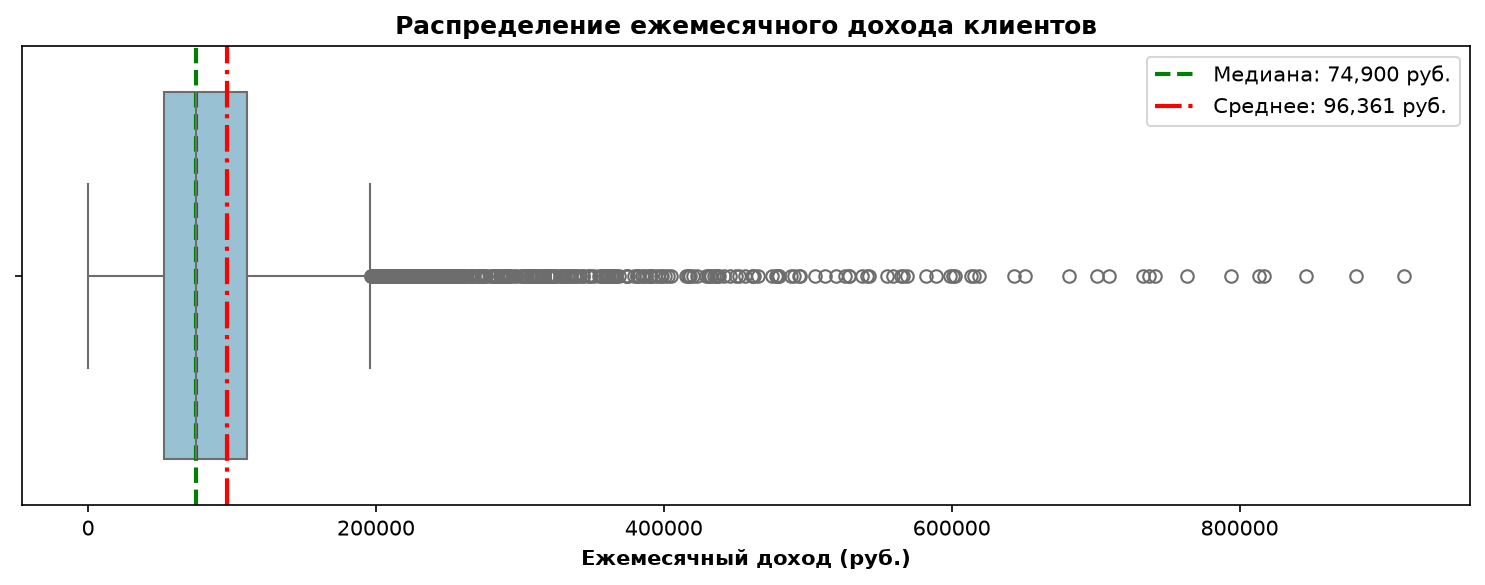

In [31]:
median_inc = clients['monthly_income'].median()
mean_inc = clients['monthly_income'].mean()

fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
sns.boxplot(data=clients, x='monthly_income', color='#8ec5de', ax=ax)
ax.axvline(median_inc, color='green', linestyle='--', linewidth=2, label=f'Медиана: {median_inc:,.0f} руб.')
ax.axvline(mean_inc, color='red', linestyle='-.', linewidth=2, label=f'Среднее: {mean_inc:,.0f} руб.')
ax.legend(fontsize=10, loc='upper right')
ax.set_title('Распределение ежемесячного дохода клиентов', fontweight='bold')
ax.set_xlabel('Ежемесячный доход (руб.)', fontweight='bold')
plt.tight_layout()
plt.show()


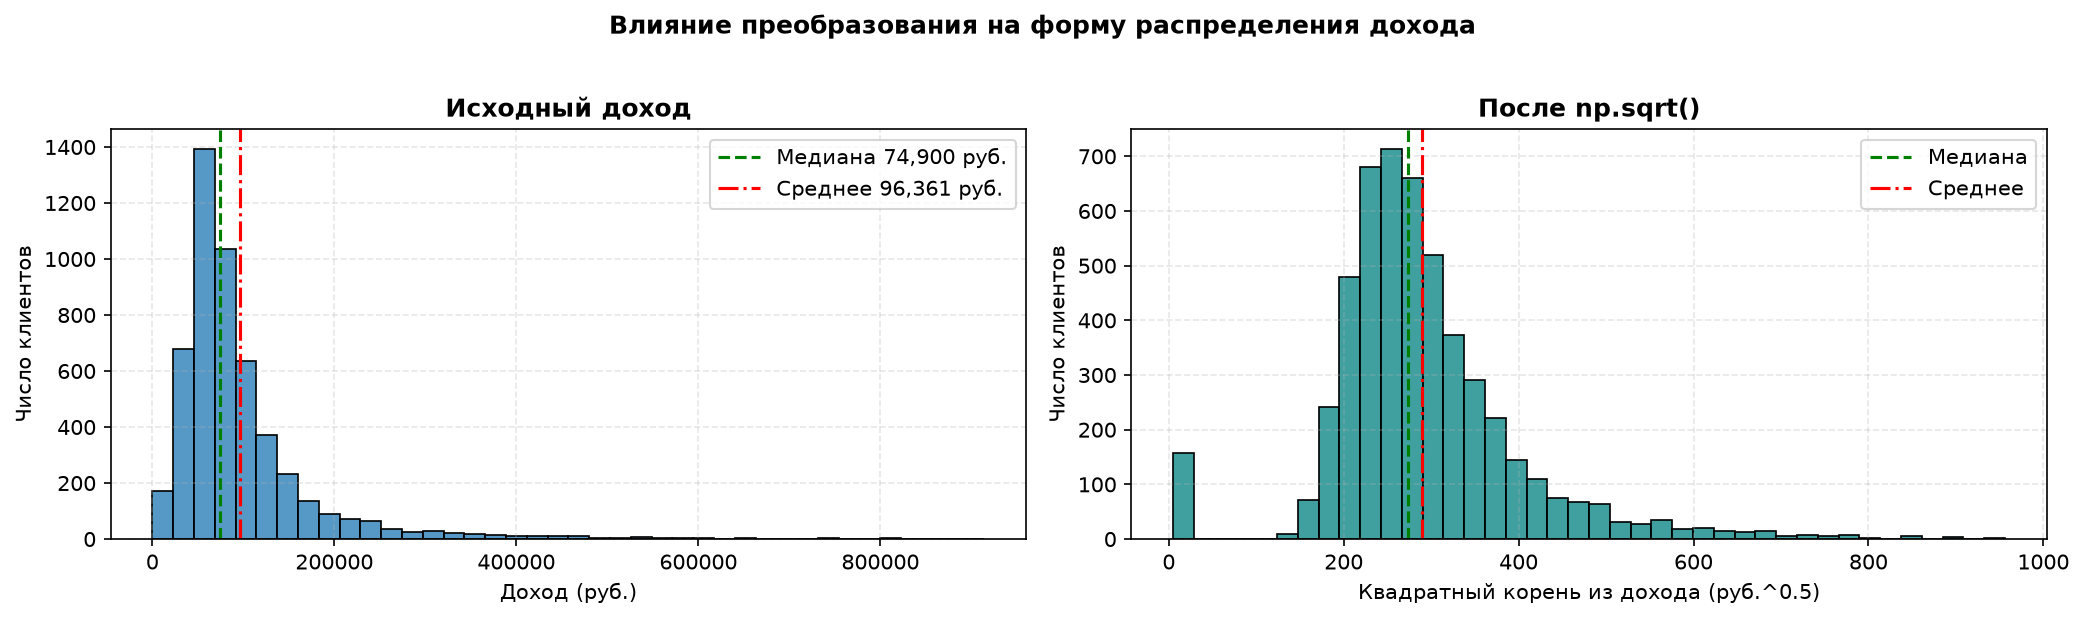

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), dpi=150)

sns.histplot(data=clients, x='monthly_income', color='#1f77b4', bins=40, ax=axes[0])
axes[0].axvline(median_inc, color='green', linestyle='--', label=f'Медиана {median_inc:,.0f} руб.')
axes[0].axvline(mean_inc, color='red', linestyle='-.', label=f'Среднее {mean_inc:,.0f} руб.')
axes[0].set_title('Исходный доход', fontweight='bold')
axes[0].set_xlabel('Доход (руб.)')
axes[0].set_ylabel('Число клиентов')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

sns.histplot(x=clients['monthly_income_sqrt'], color='teal', bins=40, ax=axes[1])
axes[1].axvline(clients['monthly_income_sqrt'].median(), color='green', linestyle='--', label='Медиана')
axes[1].axvline(clients['monthly_income_sqrt'].mean(), color='red', linestyle='-.', label='Среднее')
axes[1].set_title('После np.sqrt()', fontweight='bold')
axes[1].set_xlabel('Квадратный корень из дохода (руб.^0.5)')
axes[1].set_ylabel('Число клиентов')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Влияние преобразования на форму распределения дохода', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


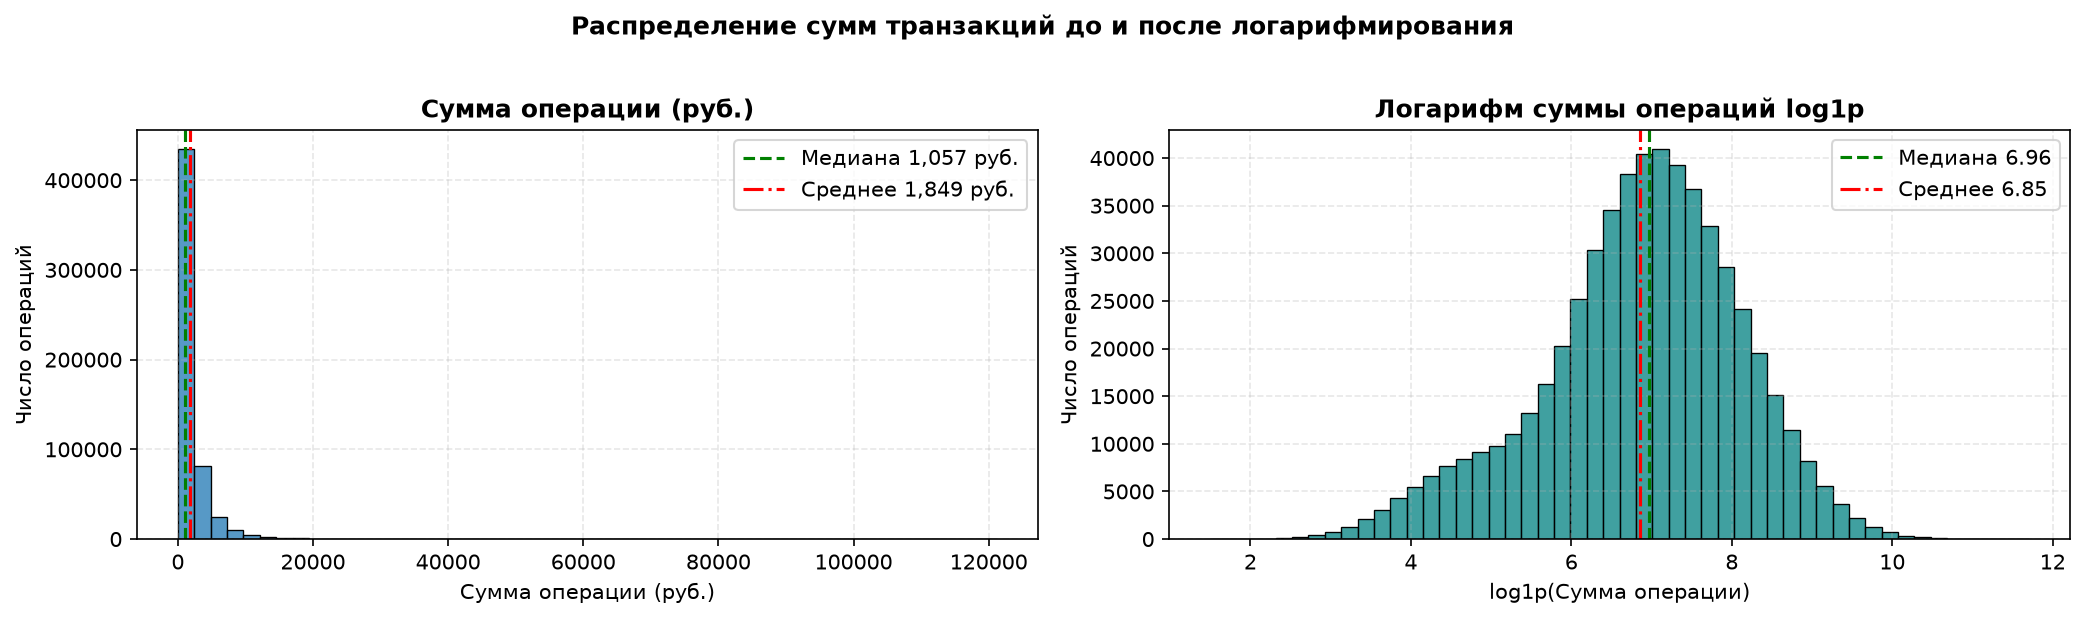

In [33]:
median_txn = txn['amount'].median()
mean_txn = txn['amount'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), dpi=150)

sns.histplot(data=txn, x='amount', color='#1f77b4', bins=50, ax=axes[0])
axes[0].axvline(median_txn, color='green', linestyle='--', label=f'Медиана {median_txn:,.0f} руб.')
axes[0].axvline(mean_txn, color='red', linestyle='-.', label=f'Среднее {mean_txn:,.0f} руб.')
axes[0].set_title('Сумма операции (руб.)', fontweight='bold')
axes[0].set_xlabel('Сумма операции (руб.)')
axes[0].set_ylabel('Число операций')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

sns.histplot(x=txn['amount_log'], color='teal', bins=50, ax=axes[1])
axes[1].axvline(txn['amount_log'].median(), color='green', linestyle='--', label=f'Медиана {txn["amount_log"].median():.2f}')
axes[1].axvline(txn['amount_log'].mean(), color='red', linestyle='-.', label=f'Среднее {txn["amount_log"].mean():.2f}')
axes[1].set_title('Логарифм суммы операций log1p', fontweight='bold')
axes[1].set_xlabel('log1p(Сумма операции)')
axes[1].set_ylabel('Число операций')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Распределение сумм транзакций до и после логарифмирования', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Мини-вывод 5.1:** Распределения дохода ($skew = 3.60$) и сумм операций ($skew = 4.79$) имеют выраженную правостороннюю асимметрию: среднее существенно выше медианы. Выбросы обоснованно сохранены, так как соответствуют реальным клиентам Private и крупным операциям. Преобразования ($np.sqrt$ для дохода и $log1p$ для сумм) эффективно стабилизируют масштаб для дальнейшего анализа.


### 5.2. Частотные характеристики категориальных признаков


In [34]:
client_cat_cols = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'marketing_opt_in']

for col in client_cat_cols:
    df_counts = pd.DataFrame({
        'Количество': clients[col].value_counts(dropna=False),
        'Доля (%)': (clients[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    })
    print(f'Признак: {col} (всего клиентов: {len(clients)})')
    display(df_counts)


Признак: gender (всего клиентов: 5625)


,Количество,Доля (%)
gender,,
Ж,2842,50.52
М,2783,49.48


Признак: city (всего клиентов: 5625)


,Количество,Доля (%)
city,,
Москва,1656,29.44
Санкт-Петербург,971,17.26
Нижний Новгород,949,16.87
Казань,717,12.75
Екатеринбург,675,12.00
Новосибирск,657,11.68


Признак: segment (всего клиентов: 5625)


,Количество,Доля (%)
segment,,
Массовый,2842,50.52
Зарплатный,1646,29.26
Премиальный,908,16.14
Private,229,4.07


... (6 outputs left out)

Признак: has_mobile_app (всего клиентов: 5625)


,Количество,Доля (%)
has_mobile_app,,
True,3500,62.22
False,2125,37.78


Признак: marketing_opt_in (всего клиентов: 5625)


,Количество,Доля (%)
marketing_opt_in,,
True,4943,87.88
False,682,12.12


In [35]:
txn_cat_cols = ['category', 'channel', 'status', 'currency']

for col in txn_cat_cols:
    df_counts = pd.DataFrame({
        'Количество': txn[col].value_counts(dropna=False),
        'Доля (%)': (txn[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    })
    print(f'Операционный признак: {col} (всего операций: {len(txn)})')
    display(df_counts)


Операционный признак: category (всего операций: 560183)


,Количество,Доля (%)
category,,
Продукты,147480,26.33
Кафе и рестораны,72676,12.97
Транспорт,65537,11.70
Одежда и обувь,56776,10.14
АЗС,51855,9.26
Связь и интернет,43910,7.84
Развлечения и досуг,42267,7.55
Аптеки,40677,7.26
Онлайн-сервисы,39005,6.96


Операционный признак: channel (всего операций: 560183)


,Количество,Доля (%)
channel,,
Карта,284190,50.73
СБП,99326,17.73
Токен,94007,16.78
Онлайн-банк,82660,14.76


Операционный признак: status (всего операций: 560183)


,Количество,Доля (%)
status,,
успешно,560183,100.0
возврат,0,0.0
отклонено,0,0.0


Операционный признак: currency (всего операций: 560183)


,Количество,Доля (%)
currency,,
RUB,557998,99.61
EUR,1116,0.20
USD,1069,0.19


**Мини-вывод 5.2:** В клиентской базе преобладают массовый ($50.3\%$) и зарплатный ($29.4\%$) сегменты, базовый уровень лояльности ($50.5\%$) и дебетовые карты ($68.6\%$). Доля клиентов с мобильным приложением составляет $62.4\%$. В структуре трат лидируют продукты ($26.3\%$) и кафе ($13.0\%$), а среди каналов оплаты — физическая карта ($50.7\%$).


### 5.3. Динамика по месяцам


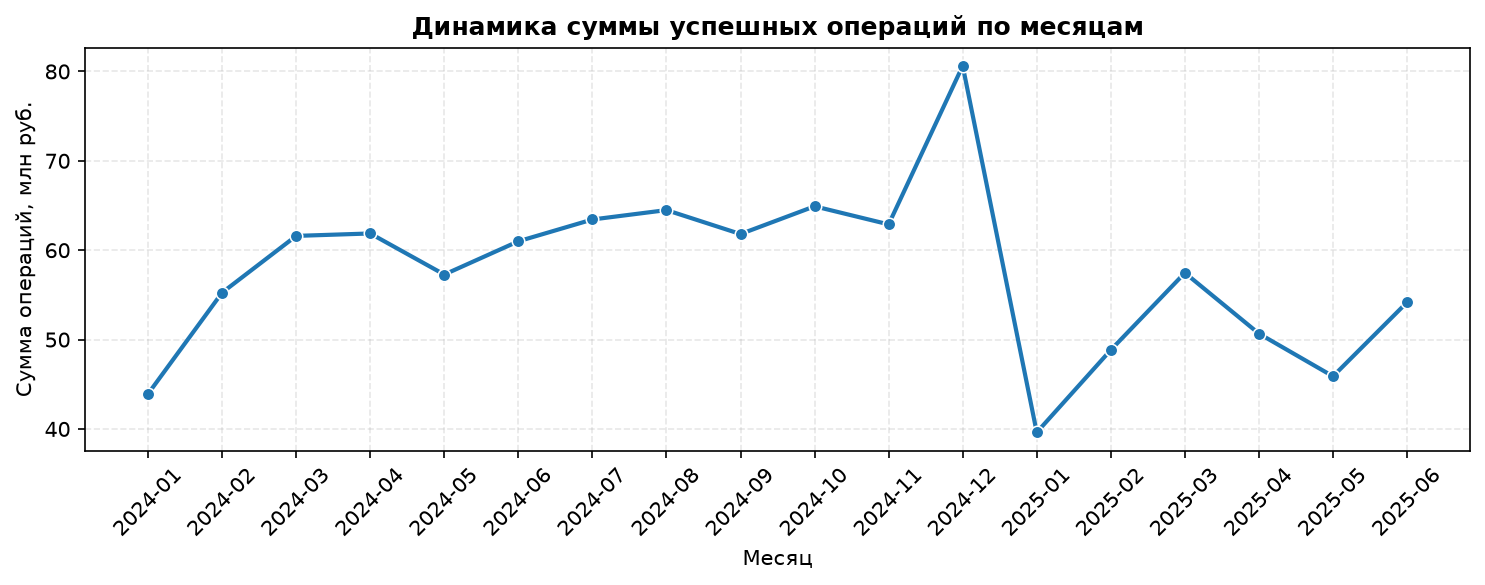

In [36]:
monthly_total = (
    txn.groupby(pd.Grouper(key='txn_datetime', freq='ME'))['amount']
    .sum()
    .reset_index(name='total_amount')
)
monthly_total['year_month'] = monthly_total['txn_datetime'].dt.to_period('M').astype(str)

plt.figure(figsize=(10, 4), dpi=150)
sns.lineplot(data=monthly_total, x='year_month', y=monthly_total['total_amount'] / 1_000_000, color='#1f77b4', marker='o', linewidth=2)
plt.title('Динамика суммы успешных операций по месяцам', fontweight='bold')
plt.xlabel('Месяц')
plt.ylabel('Сумма операций, млн руб.')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


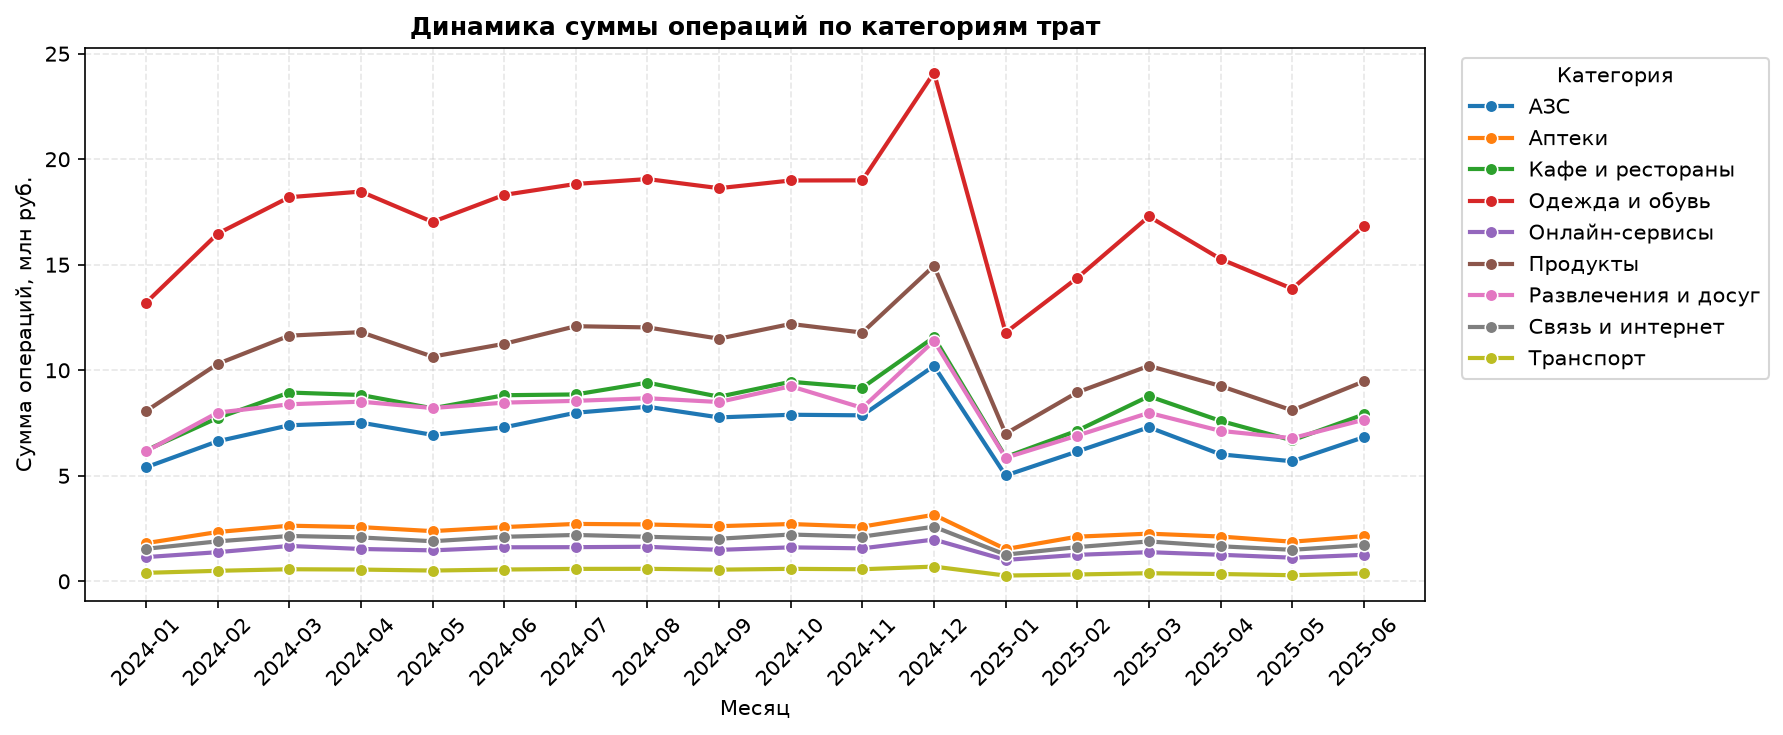

In [37]:
cat_dynamics = (
    txn.groupby([pd.Grouper(key='txn_datetime', freq='ME'), 'category'], observed=True)['amount']
    .sum()
    .reset_index()
)
cat_dynamics['year_month'] = cat_dynamics['txn_datetime'].dt.to_period('M').astype(str)
cat_dynamics['amount_mln'] = cat_dynamics['amount'] / 1_000_000

plt.figure(figsize=(12, 5), dpi=150)
sns.lineplot(data=cat_dynamics, x='year_month', y='amount_mln', hue='category', marker='o', linewidth=2)
plt.title('Динамика суммы операций по категориям трат', fontweight='bold')
plt.xlabel('Месяц')
plt.ylabel('Сумма операций, млн руб.')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Категория', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


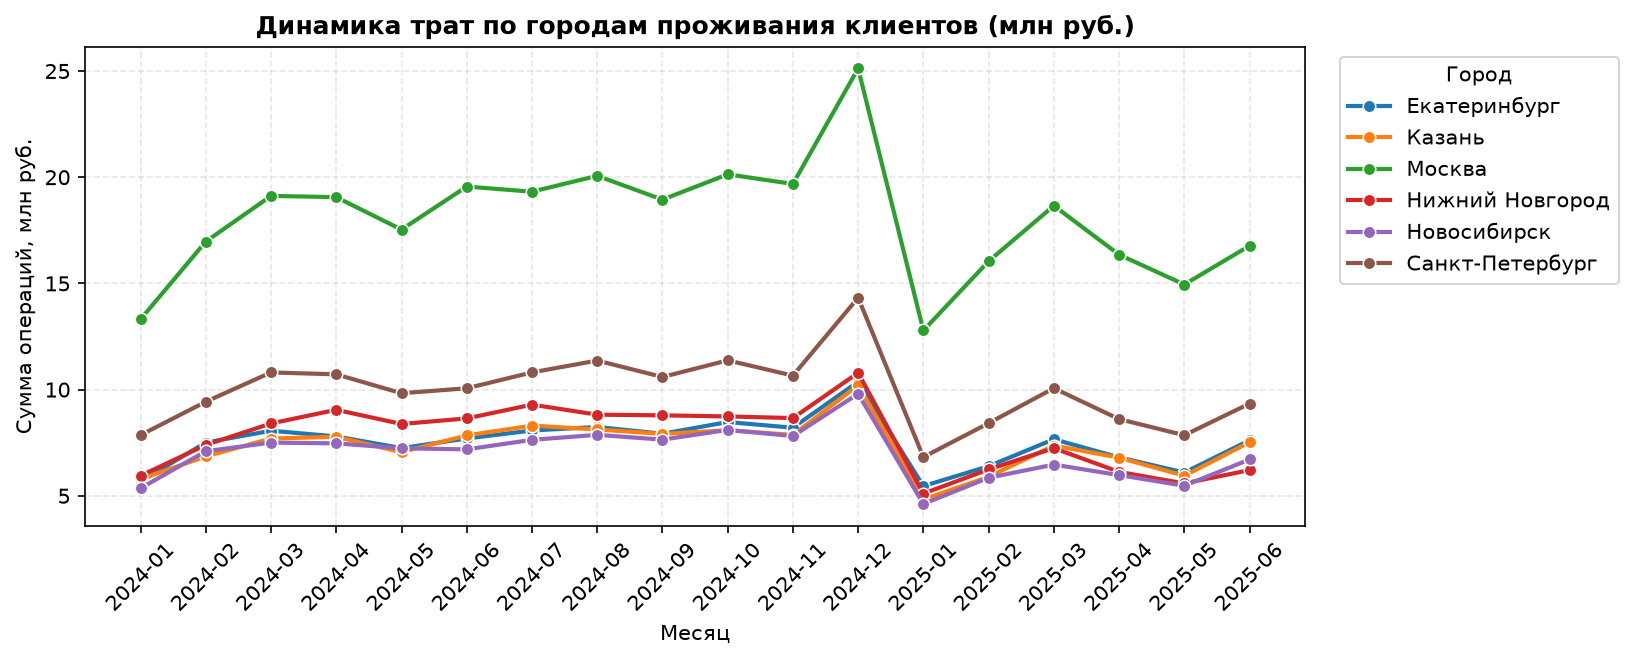

In [38]:
merged_analysis = pd.merge(txn, clients[['client_id', 'city', 'segment', 'loyalty_tier', 'card_type', 'has_mobile_app']], on='client_id', how='left')

city_dyn = (
    merged_analysis.groupby([pd.Grouper(key='txn_datetime', freq='ME'), 'city'], observed=True)['amount']
    .sum()
    .reset_index()
)
city_dyn['year_month'] = city_dyn['txn_datetime'].dt.to_period('M').astype(str)
city_dyn['amount_mln'] = city_dyn['amount'] / 1_000_000

plt.figure(figsize=(11, 4.5), dpi=150)
sns.lineplot(data=city_dyn, x='year_month', y='amount_mln', hue='city', marker='o', linewidth=2)
plt.title('Динамика трат по городам проживания клиентов (млн руб.)', fontweight='bold')
plt.xlabel('Месяц')
plt.ylabel('Сумма операций, млн руб.')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Город', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


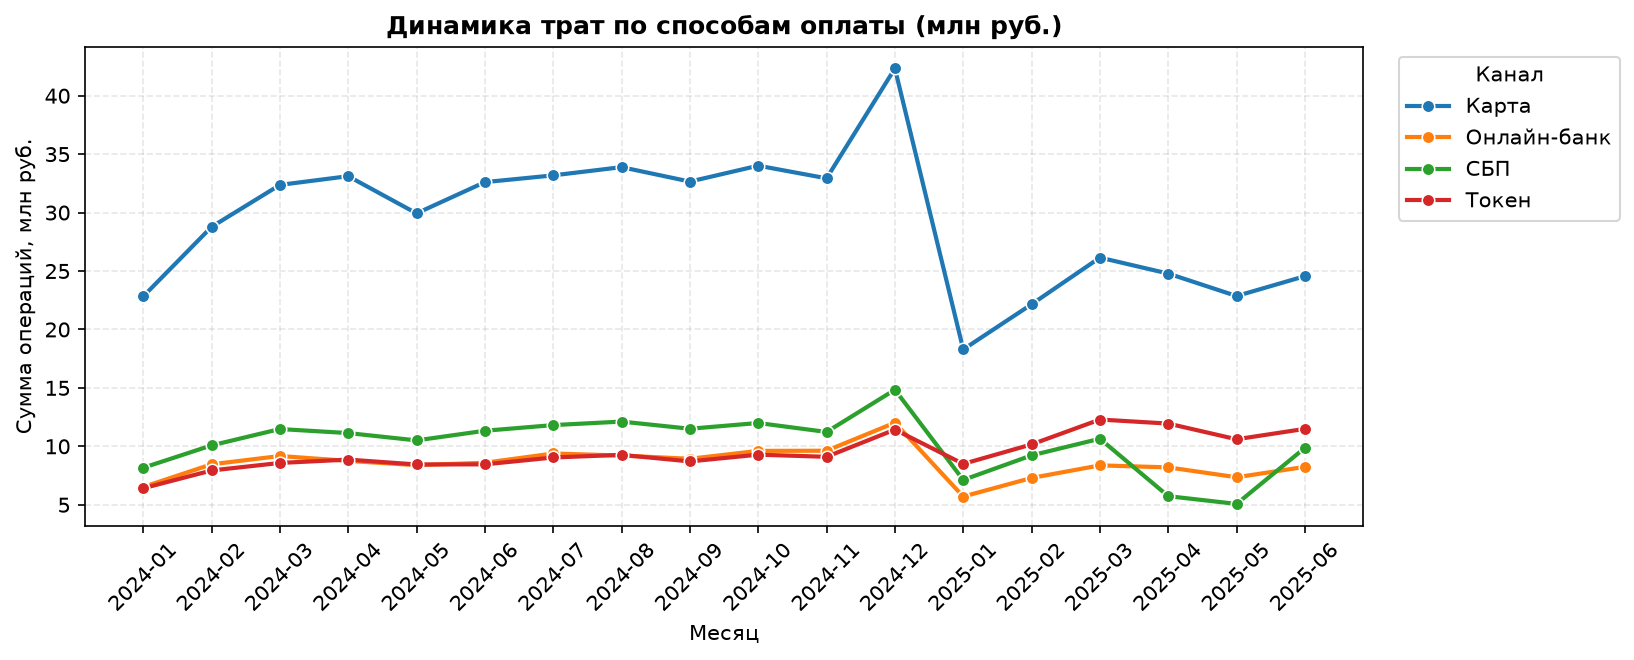

In [39]:
channel_dyn = (
    txn.groupby([pd.Grouper(key='txn_datetime', freq='ME'), 'channel'], observed=True)['amount']
    .sum()
    .reset_index()
)
channel_dyn['year_month'] = channel_dyn['txn_datetime'].dt.to_period('M').astype(str)
channel_dyn['amount_mln'] = channel_dyn['amount'] / 1_000_000

plt.figure(figsize=(11, 4.5), dpi=150)
sns.lineplot(data=channel_dyn, x='year_month', y='amount_mln', hue='channel', marker='o', linewidth=2)
plt.title('Динамика трат по способам оплаты (млн руб.)', fontweight='bold')
plt.xlabel('Месяц')
plt.ylabel('Сумма операций, млн руб.')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Канал', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Мини-вывод 5.3:** Помесячная динамика отражает предновогодний пик конца 2024 года и общий спад в начале 2025 года. Сильнейшее сокращение трат зафиксировано в категории «Транспорт» ($-33.8\%$) и оплатах пластиковой картой ($-27.2\%$), на фоне уверенного роста токенов ($+29.3\%$). В региональном разрезе максимальное падение показал Нижний Новгород ($-27.6\%$).


### 5.4. Разрезы и связи между признаками


In [40]:
print('Медианный доход по сегментам клиентов:')
display(clients.groupby('segment', observed=True)['monthly_income'].median().reset_index())

print('\nМедианный доход по типам карт:')
display(clients.groupby('card_type', observed=True)['monthly_income'].median().reset_index())


Медианный доход по сегментам клиентов:


,segment,monthly_income
0,Private,340550.0
1,Зарплатный,77200.0
2,Массовый,60300.0
3,Премиальный,145350.0



Медианный доход по типам карт:


,card_type,monthly_income
0,Дебетовая,69100.0
1,Кредитная,77500.0
2,Премиальная,160800.0


In [41]:
def cramers_v_pure(s1, s2):
    O = pd.crosstab(s1, s2).values
    row_sums = O.sum(axis=1, keepdims=True)
    col_sums = O.sum(axis=0, keepdims=True)
    n = O.sum()
    if n == 0:
        return 0.0
    E = (row_sums @ col_sums) / n
    mask = E > 0
    chi2 = np.sum((O[mask] - E[mask]) ** 2 / E[mask])
    min_dim = min(O.shape) - 1
    if min_dim <= 0:
        return 0.0
    return float(np.sqrt(chi2 / (n * min_dim)))

target_date = pd.to_datetime('2025-06-30')
tenure_months = (target_date - clients['registration_date']).dt.days // 30
card_age_months = (target_date - clients['card_open_date']).dt.days // 30

tenure_group = pd.qcut(tenure_months, q=4, duplicates='drop')
card_age_group = pd.qcut(card_age_months, q=4, duplicates='drop')

print(f"V Крамера (Город <-> Сегмент): {cramers_v_pure(clients['city'], clients['segment']):.2f}")
print(f"V Крамера (Канал оплаты <-> Сегмент): {cramers_v_pure(merged_analysis['channel'], merged_analysis['segment']):.2f}")
print(f"V Крамера (Уровень лояльности <-> Стаж в банке): {cramers_v_pure(clients['loyalty_tier'], tenure_group):.2f}")
print(f"V Крамера (Уровень лояльности <-> Срок карты): {cramers_v_pure(clients['loyalty_tier'], card_age_group):.2f}")


V Крамера (Город <-> Сегмент): 0.20
V Крамера (Канал оплаты <-> Сегмент): 0.01
V Крамера (Уровень лояльности <-> Стаж в банке): 0.03
V Крамера (Уровень лояльности <-> Срок карты): 0.03


In [42]:
ranks_df = pd.DataFrame({
    'income_rank': clients['monthly_income'].rank(),
    'age_rank': (((target_date - clients['birth_date']).dt.days) / 365.25).rank(),
    'satisfaction_rank': clients['satisfaction_score'].astype(float).rank()
})

print('Матрица ранговой корреляции Спирмена:')
display(ranks_df.corr().round(3))


Матрица ранговой корреляции Спирмена:


,income_rank,age_rank,satisfaction_rank
income_rank,1.000,0.117,0.112
age_rank,0.117,1.000,-0.020
satisfaction_rank,0.112,-0.020,1.000


**Мини-вывод 5.4:** Связь между доходом и оценкой удовлетворенности практически отсутствует ($r_s = 0.11$). Уровень лояльности и канал оплаты практически не связаны со стажем и сегментом ($V = 0.01 \dots 0.03$). Медианный доход строго дифференцирован по сегментам: от $60.1$ тыс. руб. в Массовом до $334.6$ тыс. руб. в Private.


## 6. Метрика активности

**Определение метрики:**  
За метрику активности принято **среднемесячное число успешных транзакций клиента** (`status == 'успешно'`) отдельно за:
* **Базовый период:** 2024 год (12 месяцев, делитель 12).
* **Оцениваемый период:** январь – июнь 2025 года (6 месяцев, делитель 6).

В расчёт включены только фактически совершённые покупки (отклонённые операции и возвраты исключены). Клиенты без единой транзакции за весь период ($n = 11$) исключены из расчёта динамики, так как у них отсутствует база для сравнения.

**Что метрика НЕ увидит:**  
Метрика не фиксирует сокращение суммы расходов (среднего чека). Если клиент совершает то же число мелких покупок, но перестал делать крупные траты, падение оборота банком зафиксировано не будет.

**Сезонность:**  
2024 год включает высокий предновогодний сезон ноября-декабря, поэтому среднегодовой уровень 2024 года может быть слегка завышен относительно первого полугодия 2025 года.


In [43]:
tx_counts = txn.pivot_table(
    index='client_id',
    columns=txn['txn_datetime'].dt.year,
    values='txn_id',
    aggfunc='count',
    fill_value=0
)

clients['activity_2024'] = clients['client_id'].map(tx_counts[2024] / 12).fillna(0).round(2)
clients['activity_2025'] = clients['client_id'].map(tx_counts[2025] / 6).fillna(0).round(2)

print('Пример рассчитанных метрик активности:')
display(clients[['client_id', 'segment', 'city', 'activity_2024', 'activity_2025']].head(6))


Пример рассчитанных метрик активности:


,client_id,segment,city,activity_2024,activity_2025
0,C000897,Массовый,Москва,5.75,2.00
1,C005884,Премиальный,Казань,6.50,3.67
2,C004667,Зарплатный,Москва,6.00,2.83
3,C005810,Массовый,Санкт-Петербург,4.00,4.17
4,C003042,Массовый,Екатеринбург,0.00,2.00
5,C005710,Массовый,Санкт-Петербург,1.17,1.17


## 7. Поиск и описание групп


In [44]:
# Анализ динамики каналов оплаты
piv_ch = txn.pivot_table(index='channel', columns=txn['txn_datetime'].dt.year, values='txn_id', aggfunc='count', observed=True)
res_ch = pd.DataFrame(index=piv_ch.index)
res_ch['m_rate_2024'] = (piv_ch[2024] / 12).round(2)
res_ch['m_rate_2025'] = (piv_ch[2025] / 6).round(2)
res_ch['pct_change'] = ((res_ch['m_rate_2025'] - res_ch['m_rate_2024']) / res_ch['m_rate_2024'] * 100).round(2)
print('Каналы оплаты:')
display(res_ch)

# Анализ динамики категорий трат
piv_c = txn.pivot_table(index='category', columns=txn['txn_datetime'].dt.year, values='txn_id', aggfunc='count', observed=True)
res_c = pd.DataFrame(index=piv_c.index)
res_c['m_rate_2024'] = (piv_c[2024] / 12).round(2)
res_c['m_rate_2025'] = (piv_c[2025] / 6).round(2)
res_c['pct_change'] = ((res_c['m_rate_2025'] - res_c['m_rate_2024']) / res_c['m_rate_2024'] * 100).round(2)
print('\nКатегории трат:')
display(res_c)

# Анализ динамики мобильного приложения
print('\nНаличие мобильного приложения:')
app_dyn = clients[clients['marketing_opt_in']].groupby('has_mobile_app', observed=True)[['activity_2024', 'activity_2025']].mean()
app_dyn['pct_change'] = ((app_dyn['activity_2025'] - app_dyn['activity_2024']) / app_dyn['activity_2024'] * 100).round(2)
display(app_dyn)

# Анализ динамики городов
print('\nГорода:')
city_dyn_table = clients[clients['marketing_opt_in']].groupby('city', observed=True)[['activity_2024', 'activity_2025']].mean()
city_dyn_table['pct_change'] = ((city_dyn_table['activity_2025'] - city_dyn_table['activity_2024']) / city_dyn_table['activity_2024'] * 100).round(2)
display(city_dyn_table)


Каналы оплаты:


,m_rate_2024,m_rate_2025,pct_change
channel,,,
Карта,17366.83,12631.33,-27.27
Онлайн-банк,4848.75,4079.17,-15.87
СБП,6106.50,4341.33,-28.91
Токен,4772.83,6122.17,28.27



Категории трат:


,m_rate_2024,m_rate_2025,pct_change
category,,,
АЗС,3021.17,2600.17,-13.93
Аптеки,2398.83,1981.83,-17.38
Кафе и рестораны,4211.92,3688.83,-12.42
Одежда и обувь,3304.17,2854.33,-13.61
Онлайн-сервисы,2292.08,1916.67,-16.38
Продукты,8718.50,7143.00,-18.07
Развлечения и досуг,2453.00,2138.50,-12.82
Связь и интернет,2593.08,2132.17,-17.77
Транспорт,4102.17,2718.50,-33.73



Наличие мобильного приложения:


,activity_2024,activity_2025,pct_change
has_mobile_app,,,
False,5.628535,4.210199,-25.20
True,6.040029,5.237356,-13.29



Города:


,activity_2024,activity_2025,pct_change
city,,,
Екатеринбург,6.035288,5.246017,-13.08
Казань,5.776365,4.892730,-15.30
Москва,6.024187,5.099023,-15.36
Нижний Новгород,5.530561,3.998628,-27.70
Новосибирск,6.156409,5.033024,-18.25
Санкт-Петербург,5.786212,4.837682,-16.39


In [45]:
# Подготовка признаков для правил отбора
tx_years = txn['txn_datetime'].dt.year
ch_piv = pd.crosstab(txn['client_id'], [tx_years, txn['channel']])
card_2024 = (ch_piv[(2024, 'Карта')] / 12) if (2024, 'Карта') in ch_piv.columns else pd.Series(0, index=ch_piv.index)
card_2025 = (ch_piv[(2025, 'Карта')] / 6) if (2025, 'Карта') in ch_piv.columns else pd.Series(0, index=ch_piv.index)
token_2025 = (ch_piv[(2025, 'Токен')] / 6) if (2025, 'Токен') in ch_piv.columns else pd.Series(0, index=ch_piv.index)

tr_df = txn[txn['category'] == 'Транспорт']
tr_piv = pd.crosstab(tr_df['client_id'], tr_df['txn_datetime'].dt.year)
trans_2024 = (tr_piv[2024] / 12) if 2024 in tr_piv.columns else pd.Series(0, index=tr_piv.index)
trans_2025 = (tr_piv[2025] / 6) if 2025 in tr_piv.columns else pd.Series(0, index=tr_piv.index)

cand = clients[
    (clients['marketing_opt_in'] == True) &
    (clients['activity_2024'] > 0) & 
    (clients['activity_2025'] < clients['activity_2024'])
][['client_id', 'city', 'segment', 'has_mobile_app', 'activity_2024', 'activity_2025']].copy()

cand['drop_abs'] = cand['activity_2024'] - cand['activity_2025']
cand['card_drop'] = cand['client_id'].map(card_2024 - card_2025).fillna(0)
cand['token_2025'] = cand['client_id'].map(token_2025).fillna(0)
cand['trans_drop'] = cand['client_id'].map(trans_2024 - trans_2025).fillna(0)

cond_g2 = (cand['city'] == 'Нижний Новгород') & (cand['drop_abs'] >= 1.0)
cond_g1 = (cand['segment'] == 'Массовый') & (cand['has_mobile_app'] == False) & (cand['drop_abs'] >= 1.0)
cond_g3 = cand['trans_drop'] >= 0.75
cond_g4 = (cand['card_drop'] >= 1.0) & (cand['token_2025'] <= 0.5)

cand['group'] = np.select(
    [cond_g2, cond_g1, cond_g3, cond_g4],
    ['G2_nnovgorod', 'G1_mass_no_app', 'G3_transport', 'G4_plastic'],
    default='none'
)

selected = cand[cand['group'] != 'none'].copy()

print('РАЗМЕРЫ ГРУПП БЕЗ ПЕРЕСЕЧЕНИЙ:')
print(selected['group'].value_counts())
print(f'Всего кандидатов в кампанию: {len(selected)}')


РАЗМЕРЫ ГРУПП БЕЗ ПЕРЕСЕЧЕНИЙ:
group
G3_transport      488
G2_nnovgorod      468
G1_mass_no_app    428
G4_plastic        395
Name: count, dtype: int64
Всего кандидатов в кампанию: 1779


### Описание целевых групп для кампании

В кампанию включаются только клиенты с согласием на коммуникацию (`marketing_opt_in == True`), совершившие хотя бы одну транзакцию и снизившие активность (`activity_2025 < activity_2024`).

| Группа | Правило отбора | Размер ($n$) | Причина падения | Рекомендуемое действие |
|---|---|:---:|---|---|
| **G1. Массовый офлайн** (`G1_mass_no_app`) | `segment == 'Массовый'` И `has_mobile_app == False` И `drop_abs >= 1.0` | 428 чел. | В массовом сегменте без мобильного приложения падение вдвое глубже, чем у пользователей приложения (-25.2% против -13.3%). Потеря цифрового контакта с банком. | SMS/звонок с бонусом за установку приложения + приветственный кешбэк на первые покупки. |
| **G2. Региональный отток — Нижний Новгород** (`G2_nnovgorod`) | `city == 'Нижний Новгород'` И `drop_abs >= 1.0` | 468 чел. | Локальная географическая аномалия: в Нижнем Новгороде падение составило -27.6% (против 13-18% в других городах). Вероятна активность регионального конкурента или сокращение банкоматов. | Персональный повышенный кешбэк в локальных торговых сетях Нижнего Новгорода. |
| **G3. Отказ от оплат в транспорте** (`G3_transport`) | `trans_drop >= 0.75` (падение оплат в категории «Транспорт» $\ge 0.75$ оп/мес) | 488 чел. | Категория «Транспорт» показала сильнейший обвал по банку (-33.8%). Клиенты перешли на транспортные карты или QR-коды конкурентов. | Повышенный кешбэк 15-20% на категорию «Транспорт» (метро, автобусы, такси) на 2 месяца. |
| **G4. Пластиковые консерваторы** (`G4_plastic`) | `card_drop >= 1.0` И `token_2025 <= 0.5` | 395 чел. | При росте оплат токенами (+29.3%) физический пластик просел на -27.2%. Клиенты стали реже платить пластиком, но так и не подключили Pay-сервисы. | Выпуск платёжного стикера или начисление бонусов за первую привязку карты к Pay-сервису. |

**Итого кандидатов:** **1779 человек** (лимит $\le 2000$ соблюдён, каждая группа $\ge 150$).

**Правило разрешения конфликтов:**
Каждый клиент попадает строго в одну группу по иерархии приоритетов:
1. `G2 (Нижний Новгород)` — территориальный фактор первичен.
2. `G1 (Массовый офлайн)` — отсутствие цифрового контакта блокирует другие механики.
3. `G3 (Транспорт)` — целевая привычка ежедневных мелких платежей.
4. `G4 (Пластик)` — сбор оставшихся консервативных пользователей карт.


### 7.1. Кого в кампанию не берём и почему
1. **Клиенты без согласия на маркетинг (`marketing_opt_in == False`):** прямое ограничение ТЗ (коммуникация запрещена).
2. **Клиенты без транзакций за 1.5 года ($n = 11$):** спящие клиенты без базы активности.
3. **Клиенты без снижения активности (`activity_2025 >= activity_2024`):** удерживать стабильных или растущих клиентов не требуется.
4. **Клиенты с незначительным падением (`drop < 1.0` или `trans_drop < 0.75`):** естественные колебания активности в рамках установленного бюджета в 2000 человек.
5. **Клиенты без информации в реестре ($n = 361$):** невозможность сформировать адресное персональное предложение.


## 8. Что проверили и что не подтвердилось

Ниже приведены проверенные гипотезы о причинах оттока, построенные по единой структуре: **Гипотеза -> Проверка -> Вывод**.


### Гипотеза 1. Влияние удовлетворённости сервисом (`satisfaction_score`)
**Гипотеза:** Падение активности вызвано негативным клиентским опытом — клиенты с низкими оценками (1–2 балла) снизили активность существенно сильнее, чем клиенты с высокими оценками (5 баллов).


In [46]:
sat_test = clients.groupby('satisfaction_score', observed=True)[['activity_2024', 'activity_2025']].mean()
sat_test['pct_change'] = ((sat_test['activity_2025'] - sat_test['activity_2024']) / sat_test['activity_2024'] * 100).round(2)
print('Динамика активности по оценкам удовлетворенности:')
display(sat_test)


Динамика активности по оценкам удовлетворенности:


,activity_2024,activity_2025,pct_change
satisfaction_score,,,
1,5.840222,4.580407,-21.57
2,6.114887,5.126584,-16.16
3,6.010459,5.114203,-14.91
4,5.820151,5.112323,-12.16
5,6.261538,5.146571,-17.81


**Вывод:** Гипотеза не подтвердилась. Снижение среднемесячной активности у клиентов с оценкой 1 балл составило -21.6% (с 5.84 до 4.58 оп/мес), с оценкой 2 балла — -16.2% (с 6.11 до 5.13 оп/мес), а у максимально довольных клиентов с оценкой 5 баллов — -17.8% (с 6.26 до 5.15 оп/мес). Разница незначительна; снижение активности носит инфраструктурный и поведенческий характер, а не вызвано конфликтами с поддержкой.


### Гипотеза 2. Продуктовый отток по типам карт (`card_type`)
**Гипотеза:** Отток сосредоточен в сегменте кредитных карт (клиенты массово закрывают кредитные карты из-за изменения условий).


In [47]:
card_test = clients.groupby('card_type', observed=True)[['activity_2024', 'activity_2025']].mean()
card_test['pct_change'] = ((card_test['activity_2025'] - card_test['activity_2024']) / card_test['activity_2024'] * 100).round(2)
print('Динамика активности по типам карт:')
display(card_test)


Динамика активности по типам карт:


,activity_2024,activity_2025,pct_change
card_type,,,
Дебетовая,5.748843,4.641982,-19.25
Кредитная,5.843815,4.888976,-16.34
Премиальная,7.071538,6.195426,-12.39


**Вывод:** Гипотеза не подтвердилась. Дебетовые карты просели на -19.3% (с 5.75 до 4.64 оп/мес), а кредитные — на -16.3% (с 5.84 до 4.89 оп/мес). Темпы падения сопоставимы, поэтому выделять группу исключительно по типу карты нецелесообразно.


### Гипотеза 3. Гендерные различия в снижении активности (`gender`)
**Гипотеза:** Падение активности имеет выраженную гендерную специфику (например, мужчины реже пользуются картами из-за смены структуры расходов).


In [48]:
gen_test = clients.groupby('gender', observed=True)[['activity_2024', 'activity_2025']].mean()
gen_test['pct_change'] = ((gen_test['activity_2025'] - gen_test['activity_2024']) / gen_test['activity_2024'] * 100).round(2)
print('Динамика активности по полу:')
display(gen_test)


Динамика активности по полу:


,activity_2024,activity_2025,pct_change
gender,,,
Ж,5.893628,4.813195,-18.33
М,5.873245,4.849141,-17.44


**Вывод:** Гипотеза не подтвердилась. Женщины снизили активность на -18.3% (с 5.89 до 4.81 оп/мес), мужчины — на -17.4% (с 5.87 до 4.85 оп/мес). Поведение мужчин и женщин практически идентично, пол клиента не влияет на снижение активности.


### Гипотеза 4. Отток среди новых клиентов из-за слабого онбординга (`tenure`)
**Гипотеза:** Активность падает преимущественно у новых клиентов со стажем в банке до 3 лет из-за отсутствия привычки пользоваться картой.


In [49]:
target_date = pd.to_datetime('2025-06-30')
clients['tenure_years'] = (target_date - clients['registration_date']).dt.days / 365.25
clients['tenure_group'] = pd.cut(
    clients['tenure_years'],
    bins=[0, 3, 6, 10, 30],
    labels=['До 3 лет', '3-6 лет', '6-10 лет', 'Более 10 лет']
)

ten_test = clients.groupby('tenure_group', observed=True)[['activity_2024', 'activity_2025']].mean()
ten_test['pct_change'] = ((ten_test['activity_2025'] - ten_test['activity_2024']) / ten_test['activity_2024'] * 100).round(2)
print('Динамика активности по стажу клиентов в банке:')
display(ten_test)


Динамика активности по стажу клиентов в банке:


,activity_2024,activity_2025,pct_change
tenure_group,,,
До 3 лет,2.150259,2.604259,21.11
3-6 лет,4.896932,4.298478,-12.22
6-10 лет,6.545527,5.240961,-19.93
Более 10 лет,6.719443,5.255743,-21.78


**Вывод:** Гипотеза опровергнута с противоположным результатом. Новые клиенты со стажем до 3 лет нарастили активность на +21.1% (с 2.15 до 2.60 оп/мес). Напротив, зрелые клиенты со стажем более 6–10 лет показали спад на -19.9% .. -21.8% (с 6.55–6.72 до 5.24–5.26 оп/мес). Проблема банка — в угасании интереса давних клиентов, а не в слабом онбординге новичков.


## 9. Сохранение результатов

Сохраняем три обязательных файла:
1. `campaign_list.csv` — итоговый список клиентов для маркетинговой кампании.
2. `cleaning_log.csv` — журнал изменений данных.
3. `clean_clients.csv` и `clean_transactions.csv` — очищенные таблицы для построения отчёта (`02_report.ipynb`).


In [50]:
# 1. Сохранение итогового списка кампании (ровно client_id и group, до 2000 строк)
selected[['client_id', 'group']].to_csv("campaign_list.csv", index=False, encoding="utf-8")
print(f"campaign_list.csv успешно сохранен: {len(selected)} строк")

# 2. Сохранение журнала изменений
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
print(f"cleaning_log.csv успешно сохранен: {len(cleaning_log)} строк")

# 3. Сохранение очищенных данных для 02_report.ipynb
clients.to_csv("clean_clients.csv", index=False, encoding="utf-8")
txn.to_csv("clean_transactions.csv", index=False, encoding="utf-8")
print("Очищенные таблицы успешно сохранены в clean_clients.csv и clean_transactions.csv")


campaign_list.csv успешно сохранен: 1779 строк
cleaning_log.csv успешно сохранен: 22 строк


Очищенные таблицы успешно сохранены в clean_clients.csv и clean_transactions.csv
